# Music & Mental Health Survey

## Stage 1: Data Understanding, Cleaning, and Preprocessing

### 1. Project Overview

This project uses the Music & Mental Health Survey Results dataset from Kaggle.

The main objective of this stage is to understand the dataset, identify data-quality problems, clean invalid values, handle missing data, investigate outliers, and compare different preprocessing methods.

This stage prepares the dataset for the next stages of the project:

2. Encoding and discretization

3. Feature selection

4. Feature construction and model performance evaluation

Important: Stage 1 focuses on data preparation. We have not performed final feature selection or predictive modeling.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer

## 2. Dataset Loading and Initial Exploration

We started by loading the CSV file using Pandas.

The following operations were performed:

- Displayed the first five observations.
- Examined the number of rows and columns.
- Inspected feature names and data types.
- Generated descriptive statistics.
- Identified numerical and categorical features.

Purpose: Understand the structure of the dataset before making any modifications.

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("catherinerasgaitis/mxmh-survey-results")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mxmh-survey-results' dataset.
Path to dataset files: /kaggle/input/mxmh-survey-results


In [3]:
df = pd.read_csv("/root/.cache/kagglehub/datasets/catherinerasgaitis/mxmh-survey-results/versions/1/mxmh_survey_results.csv")

In [4]:
print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (736, 33)


,Timestamp,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,...,Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects,Permissions
0,8/27/2022 19:29:02,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,...,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN,I understand.
1,8/27/2022 19:57:31,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,...,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN,I understand.
2,8/27/2022 21:28:18,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,...,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect,I understand.
3,8/27/2022 21:40:40,61.0,YouTube Music,2.5,Yes,No,Yes,Jazz,Yes,Yes,...,Sometimes,Never,Never,Never,9.0,7.0,3.0,3.0,Improve,I understand.
4,8/27/2022 21:54:47,18.0,Spotify,4.0,Yes,No,No,R&B,Yes,No,...,Very frequently,Very frequently,Never,Rarely,7.0,2.0,5.0,9.0,Improve,I understand.


In [5]:
DATA_PATH = "mxmh_survey_results.csv"
OUTPUT_DIR = "prepro_data"

# Possible prediction target for a later supervised-learning task.
TARGET = "Anxiety"

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [6]:
print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 736 entries, 0 to 735
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Timestamp                     736 non-null    object 
 1   Age                           735 non-null    float64
 2   Primary streaming service     735 non-null    object 
 3   Hours per day                 736 non-null    float64
 4   While working                 733 non-null    object 
 5   Instrumentalist               732 non-null    object 
 6   Composer                      735 non-null    object 
 7   Fav genre                     736 non-null    object 
 8   Exploratory                   736 non-null    object 
 9   Foreign languages             732 non-null    object 
 10  BPM                           629 non-null    float64
 11  Frequency [Classical]         736 non-null    object 
 12  Frequency [Country]           736 non-null

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Timestamp,736,735,8/28/2022 16:15:08,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,735.0,NaN,NaN,NaN,25.206803,12.05497,10.0,18.0,21.0,28.0,89.0
Primary streaming service,735,6,Spotify,458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hours per day,736.0,NaN,NaN,NaN,3.572758,3.028199,0.0,2.0,3.0,5.0,24.0
While working,733,2,Yes,579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Instrumentalist,732,2,No,497,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Composer,735,2,No,609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fav genre,736,16,Rock,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exploratory,736,2,Yes,525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Foreign languages,732,2,Yes,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Column names:
['Timestamp', 'Age', 'Primary streaming service', 'Hours per day', 'While working', 'Instrumentalist', 'Composer', 'Fav genre', 'Exploratory', 'Foreign languages', 'BPM', 'Frequency [Classical]', 'Frequency [Country]', 'Frequency [EDM]', 'Frequency [Folk]', 'Frequency [Gospel]', 'Frequency [Hip hop]', 'Frequency [Jazz]', 'Frequency [K pop]', 'Frequency [Latin]', 'Frequency [Lofi]', 'Frequency [Metal]', 'Frequency [Pop]', 'Frequency [R&B]', 'Frequency [Rap]', 'Frequency [Rock]', 'Frequency [Video game music]', 'Anxiety', 'Depression', 'Insomnia', 'OCD', 'Music effects', 'Permissions']

Data types:
Timestamp                        object
Age                             float64
Primary streaming service        object
Hours per day                   float64
While working                    object
Instrumentalist                  object
Composer                         object
Fav genre                        object
Exploratory                      object
Foreign languages    

## 3. Missing-Value Analysis

We investigated missing values using:

`isnull().sum()` to count missing values.

Missing-value percentages for each feature.

A bar chart to compare missing-value percentages.

A heatmap to visualize the distribution of missing values.

We also considered different representations of missing data:

- NaN

- NULL values

- Empty strings

- Common text representations such as "NA" and "None"

Empty strings and common missing-value strings in categorical columns were converted to NaN.

Why is this important?

Missing values can affect statistical calculations, distance-based algorithms, and machine-learning models. Therefore, they must be identified before applying preprocessing methods.

In [7]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
}).sort_values("Missing Percentage", ascending=False)

print("\nMissing values:")
display(missing_summary)


Missing values:


,Missing Count,Missing Percentage
BPM,107,14.538043
Music effects,8,1.086957
Foreign languages,4,0.543478
Instrumentalist,4,0.543478
While working,3,0.407609
Primary streaming service,1,0.135870
Composer,1,0.135870
Age,1,0.135870
Timestamp,0,0.000000
Exploratory,0,0.000000


In [8]:
# Check missing-value representations

print("NaN / NULL values:")
print(df.isnull().sum())

print("\nZero values in numeric columns:")
print((df.select_dtypes(include="number") == 0).sum())

print("\nEmpty strings:")
for col in df.select_dtypes(include="object").columns:
    count = (df[col].astype("string").str.strip() == "").sum()
    if count > 0:
        print(f"{col}: {count}")

print("\nCommon text representations:")
for col in df.select_dtypes(include="object").columns:
    values = df[col].astype("string").str.strip().str.lower()
    count = values.isin(["null", "none", "nan", "n/a", "na"]).sum()
    if count > 0:
        print(f"{col}: {count}")

NaN / NULL values:
Timestamp                         0
Age                               1
Primary streaming service         1
Hours per day                     0
While working                     3
Instrumentalist                   4
Composer                          1
Fav genre                         0
Exploratory                       0
Foreign languages                 4
BPM                             107
Frequency [Classical]             0
Frequency [Country]               0
Frequency [EDM]                   0
Frequency [Folk]                  0
Frequency [Gospel]                0
Frequency [Hip hop]               0
Frequency [Jazz]                  0
Frequency [K pop]                 0
Frequency [Latin]                 0
Frequency [Lofi]                  0
Frequency [Metal]                 0
Frequency [Pop]                   0
Frequency [R&B]                   0
Frequency [Rap]                   0
Frequency [Rock]                  0
Frequency [Video game music]      0
Anxiety  

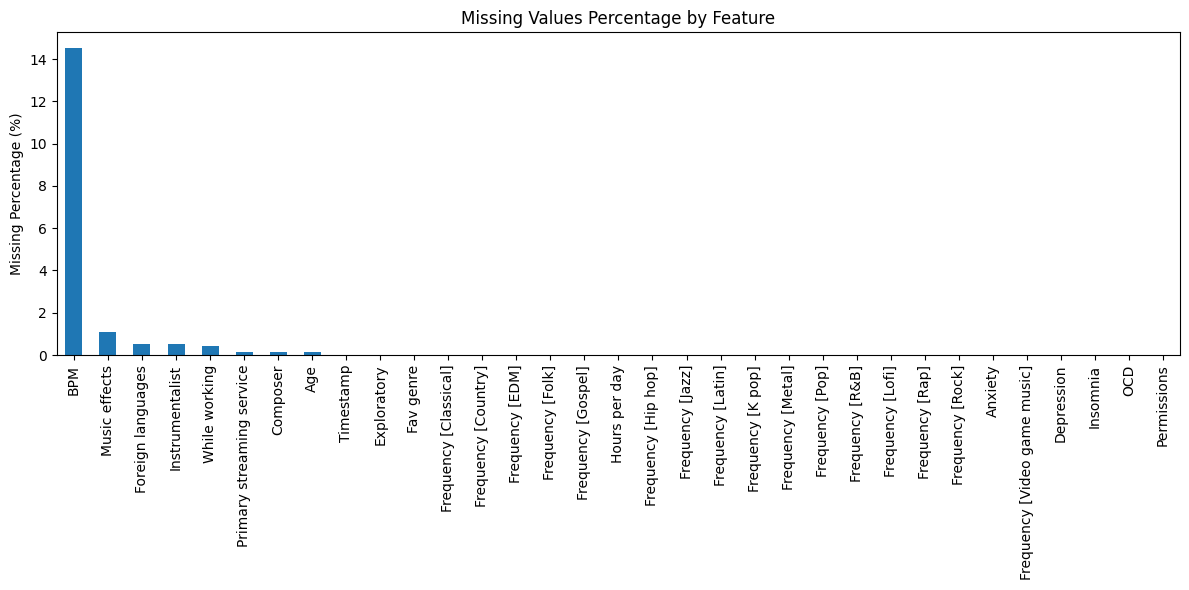

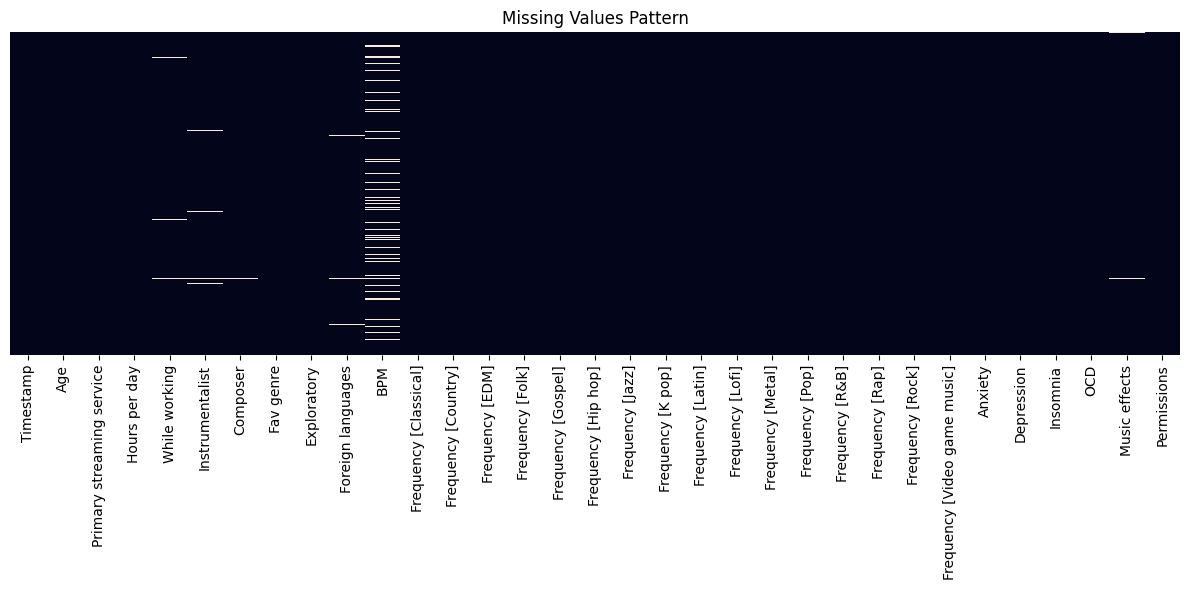

In [9]:
plt.figure(figsize=(12, 6))
missing_summary["Missing Percentage"].plot(kind="bar")
plt.title("Missing Values Percentage by Feature")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Pattern")
plt.tight_layout()
plt.show()

In [10]:
duplicate_count = df.duplicated().sum()

print("\nNumber of duplicate rows:", duplicate_count)



Number of duplicate rows: 0


In [11]:
# Remove accidental spaces around column names.
df.columns = df.columns.str.strip()

# Clean text values without encoding them.
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in categorical_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Convert empty strings and common missing-value strings to NaN.
missing_text_values = ["", "NA", "N/A", "na", "n/a", "None", "null"]

for col in categorical_columns:
    df[col] = df[col].replace(missing_text_values, np.nan)

In [12]:
# Standardize Yes/No text values while keeping them categorical.
for col in categorical_columns:
    df[col] = df[col].replace({
        "yes": "Yes",
        "YES": "Yes",
        "no": "No",
        "NO": "No"
    })

In [13]:
# Timestamp is metadata, not a useful direct predictor for this project.
if "Timestamp" in df.columns:
    df = df.drop(columns=["Timestamp"])

In [14]:
# Remove constant columns because they contain no variation.
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("\nConstant columns:", constant_columns)

df = df.drop(columns=constant_columns)

print("Shape after removing unnecessary columns:", df.shape)


Constant columns: ['Permissions']
Shape after removing unnecessary columns: (736, 31)


In [15]:
# Convert known numeric columns safely.
expected_numeric_columns = [
    "Age",
    "Hours per day",
    "BPM",
    "Anxiety",
    "Depression",
    "Insomnia",
    "OCD"
]

for col in expected_numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Invalid values are changed to NaN rather than deleting rows.
# This allows us to compare imputation methods later.

if "Age" in df.columns:
    df.loc[(df["Age"] < 10) | (df["Age"] > 100), "Age"] = np.nan

if "Hours per day" in df.columns:
    df.loc[
        (df["Hours per day"] < 0) |
        (df["Hours per day"] > 24),
        "Hours per day"
    ] = np.nan

if "BPM" in df.columns:
    # Flag invalid or implausibly high BPM values.
    df.loc[
        (df["BPM"] <= 0) | (df["BPM"] > 300),
        "BPM"
    ] = np.nan

for col in ["Anxiety", "Depression", "Insomnia", "OCD"]:
    if col in df.columns:
        df.loc[(df[col] < 0) | (df[col] > 10), col] = np.nan

print("\nData after numeric validation:")
display(df.describe().T)


Data after numeric validation:


,count,mean,std,min,25%,50%,75%,max
Age,735.0,25.206803,12.054970,10.0,18.0,21.0,28.0,89.0
Hours per day,736.0,3.572758,3.028199,0.0,2.0,3.0,5.0,24.0
BPM,624.0,123.214744,32.899605,4.0,100.0,120.0,144.0,220.0
Anxiety,736.0,5.837636,2.793054,0.0,4.0,6.0,8.0,10.0
Depression,736.0,4.796196,3.028870,0.0,2.0,5.0,7.0,10.0
Insomnia,736.0,3.738451,3.088689,0.0,1.0,3.0,6.0,10.0
OCD,736.0,2.637228,2.842017,0.0,0.0,2.0,5.0,10.0


In [16]:
# ------------------------------------------------------------
# 8. NUMERICAL VALIDATION AND DECIMAL PRECISION
# ------------------------------------------------------------

expected_numeric_columns = [
    "Age",
    "Hours per day",
    "BPM",
    "Anxiety",
    "Depression",
    "Insomnia",
    "OCD"
]

for col in expected_numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Validate numerical ranges
if "Age" in df.columns:
    df.loc[(df["Age"] < 10) | (df["Age"] > 100), "Age"] = np.nan

if "Hours per day" in df.columns:
    df.loc[
        (df["Hours per day"] < 0) |
        (df["Hours per day"] > 24),
        "Hours per day"
    ] = np.nan

if "BPM" in df.columns:
    # Flag invalid or implausibly high BPM values.
    df.loc[
        (df["BPM"] <= 0) | (df["BPM"] > 300),
        "BPM"
    ] = np.nan

for col in ["Anxiety", "Depression", "Insomnia", "OCD"]:
    if col in df.columns:
        df.loc[(df[col] < 0) | (df[col] > 10), col] = np.nan

# Display numerical values with two decimal places
pd.options.display.float_format = "{:.2f}".format

print("Numerical validation completed.")
display(df[[
    col for col in expected_numeric_columns if col in df.columns
]].describe().T)

# Recalculate missing values after numerical validation.
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary)

Numerical validation completed.


,count,mean,std,min,25%,50%,75%,max
Age,735.00,25.21,12.05,10.00,18.00,21.00,28.00,89.00
Hours per day,736.00,3.57,3.03,0.00,2.00,3.00,5.00,24.00
BPM,624.00,123.21,32.90,4.00,100.00,120.00,144.00,220.00
Anxiety,736.00,5.84,2.79,0.00,4.00,6.00,8.00,10.00
Depression,736.00,4.80,3.03,0.00,2.00,5.00,7.00,10.00
Insomnia,736.00,3.74,3.09,0.00,1.00,3.00,6.00,10.00
OCD,736.00,2.64,2.84,0.00,0.00,2.00,5.00,10.00


,Missing Count,Missing Percentage
BPM,112,15.22
Music effects,8,1.09
Foreign languages,4,0.54
Instrumentalist,4,0.54
While working,3,0.41
Composer,1,0.14
Primary streaming service,1,0.14
Age,1,0.14
Fav genre,0,0.00
Exploratory,0,0.00



Outlier analysis:


,Feature,Lower Bound,Upper Bound,Outlier Count
0,Age,3.00,43.00,59
1,Hours per day,-2.50,9.50,40
2,BPM,34.00,210.00,6
3,Anxiety,-2.00,14.00,0
4,Depression,-5.50,14.50,0
5,Insomnia,-6.50,13.50,0
6,OCD,-7.50,12.50,0


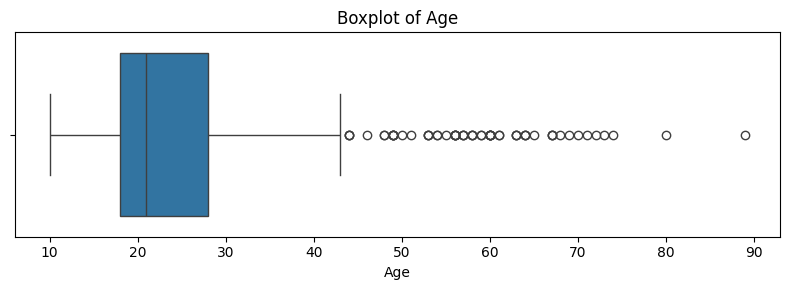

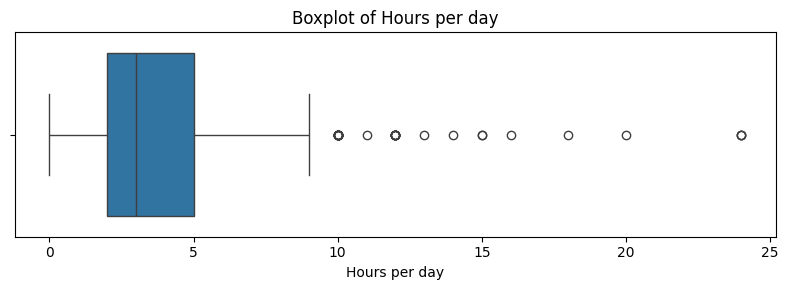

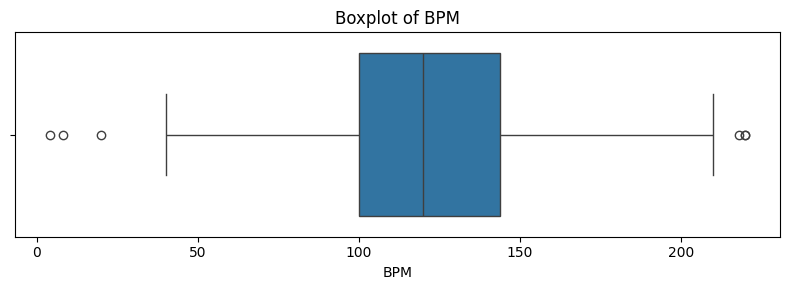

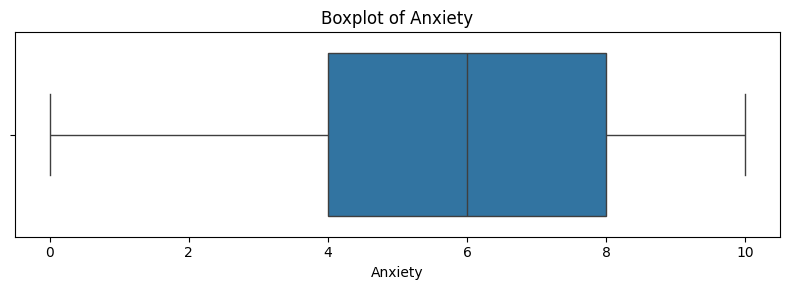

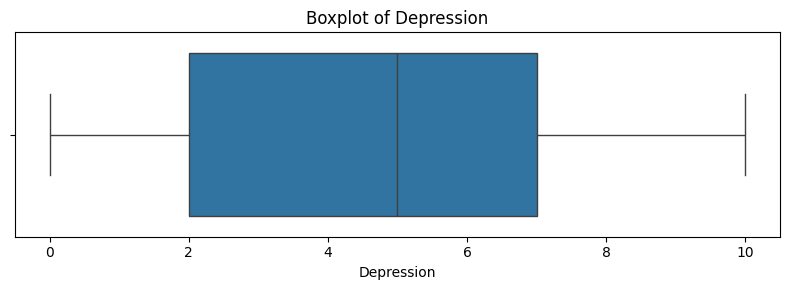

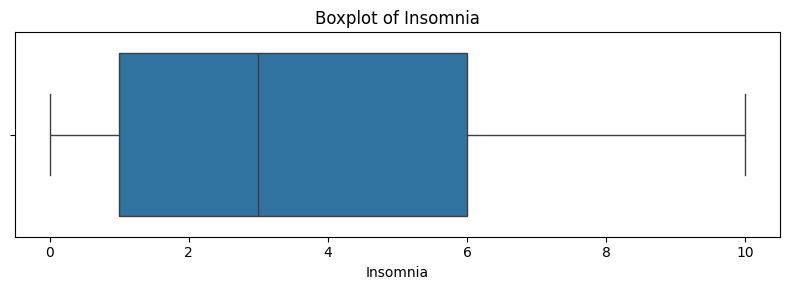

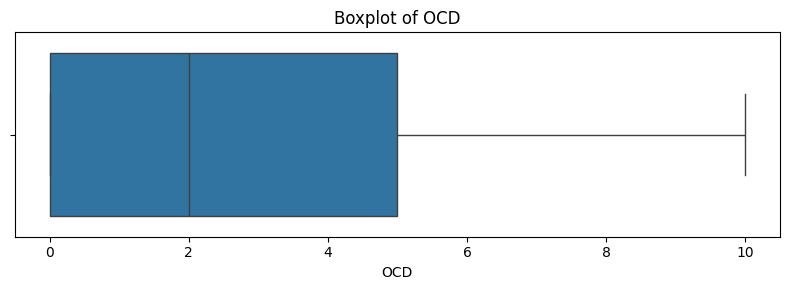

In [17]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

outlier_summary = []

for col in numeric_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

outlier_df = pd.DataFrame(outlier_summary)

print("\nOutlier analysis:")
display(outlier_df)

# Visualize numeric distributions.
for col in numeric_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

# IMPORTANT:
# We do not automatically delete outliers.
# Unusual survey responses can still be valid observations.

In [18]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

# Keep the target separate: do not impute missing target labels.
if TARGET in numeric_columns:
    numeric_predictors = [
        col for col in numeric_columns if col != TARGET
    ]
else:
    numeric_predictors = numeric_columns.copy()

categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("\nNumeric predictors:")
print(numeric_predictors)

print("\nCategorical columns:")
print(categorical_columns)


Numeric predictors:
['Age', 'Hours per day', 'BPM', 'Depression', 'Insomnia', 'OCD']

Categorical columns:
['Primary streaming service', 'While working', 'Instrumentalist', 'Composer', 'Fav genre', 'Exploratory', 'Foreign languages', 'Frequency [Classical]', 'Frequency [Country]', 'Frequency [EDM]', 'Frequency [Folk]', 'Frequency [Gospel]', 'Frequency [Hip hop]', 'Frequency [Jazz]', 'Frequency [K pop]', 'Frequency [Latin]', 'Frequency [Lofi]', 'Frequency [Metal]', 'Frequency [Pop]', 'Frequency [R&B]', 'Frequency [Rap]', 'Frequency [Rock]', 'Frequency [Video game music]', 'Music effects']


In [19]:
# 11. MISSING VALUE IMPUTATION: MEAN METHOD
# ------------------------------------------------------------

df_mean = df.copy()

# Mean imputation for numeric predictors.
if numeric_predictors:
    mean_imputer = SimpleImputer(strategy="mean")

    df_mean[numeric_predictors] = mean_imputer.fit_transform(
        df_mean[numeric_predictors]
    )

In [20]:
# Most-frequent imputation for categorical columns.
if categorical_columns:
    mode_imputer = SimpleImputer(strategy="most_frequent")

    df_mean[categorical_columns] = mode_imputer.fit_transform(
        df_mean[categorical_columns]
    )

print("\nMissing values after mean/mode imputation:")
print(df_mean.isnull().sum().sum())


Missing values after mean/mode imputation:
0


In [21]:
# 12. MISSING VALUE IMPUTATION: KNN METHOD
# ------------------------------------------------------------

df_knn = df.copy()

if numeric_predictors:
    # Scale numeric predictors temporarily before KNN.
    # This prevents variables with large ranges from dominating
    # the distance calculation.

    temporary_scaler = StandardScaler()

    numeric_scaled = temporary_scaler.fit_transform(
        df_knn[numeric_predictors]
    )

    knn_imputer = KNNImputer(
        n_neighbors=5,
        weights="distance"
    )

    numeric_imputed_scaled = knn_imputer.fit_transform(
        numeric_scaled
    )

    numeric_imputed = temporary_scaler.inverse_transform(
        numeric_imputed_scaled
    )

    df_knn[numeric_predictors] = numeric_imputed

In [22]:
# Categorical variables are not suitable for ordinary numeric KNN.
# Use the most frequent category for missing categorical values.
if categorical_columns:
    mode_imputer_knn = SimpleImputer(strategy="most_frequent")

    df_knn[categorical_columns] = mode_imputer_knn.fit_transform(
        df_knn[categorical_columns]
    )

print("\nMissing values after KNN/mode imputation:")
print(df_knn.isnull().sum().sum())


Missing values after KNN/mode imputation:
0



Mean vs KNN comparison:


,Feature,Original Missing,Mean Imputation Mean,KNN Imputation Mean,Mean Imputation Std,KNN Imputation Std
0,Age,1,25.21,25.22,12.05,12.05
1,Hours per day,0,3.57,3.57,3.03,3.03
2,BPM,112,123.21,123.14,30.29,31.08
3,Depression,0,4.80,4.80,3.03,3.03
4,Insomnia,0,3.74,3.74,3.09,3.09
5,OCD,0,2.64,2.64,2.84,2.84


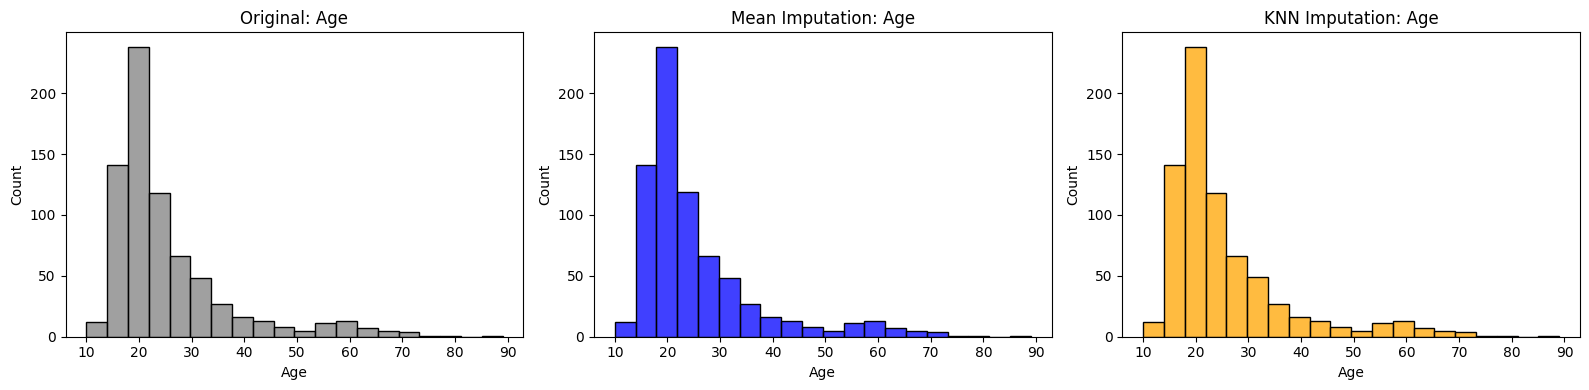

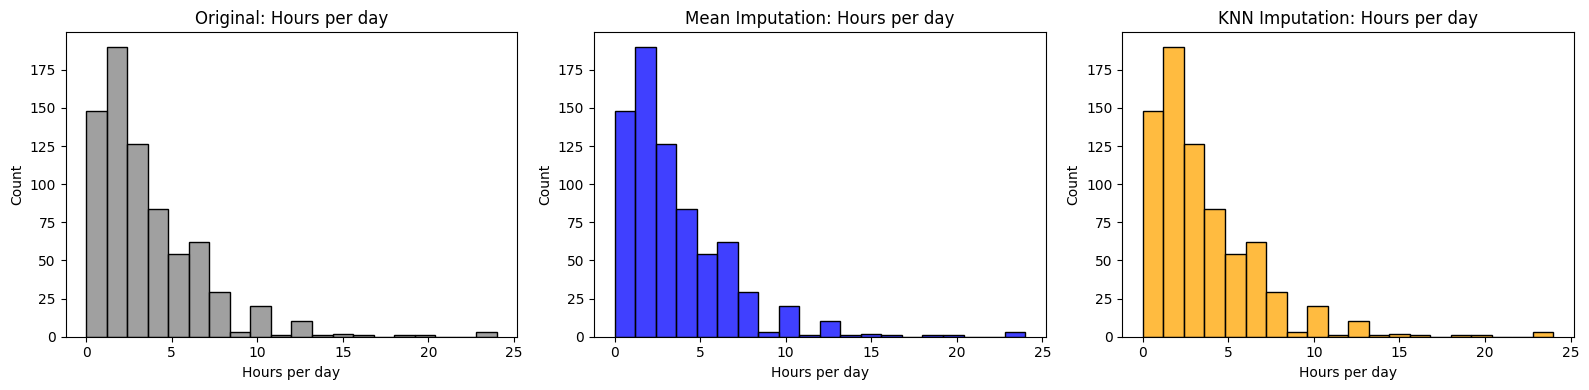

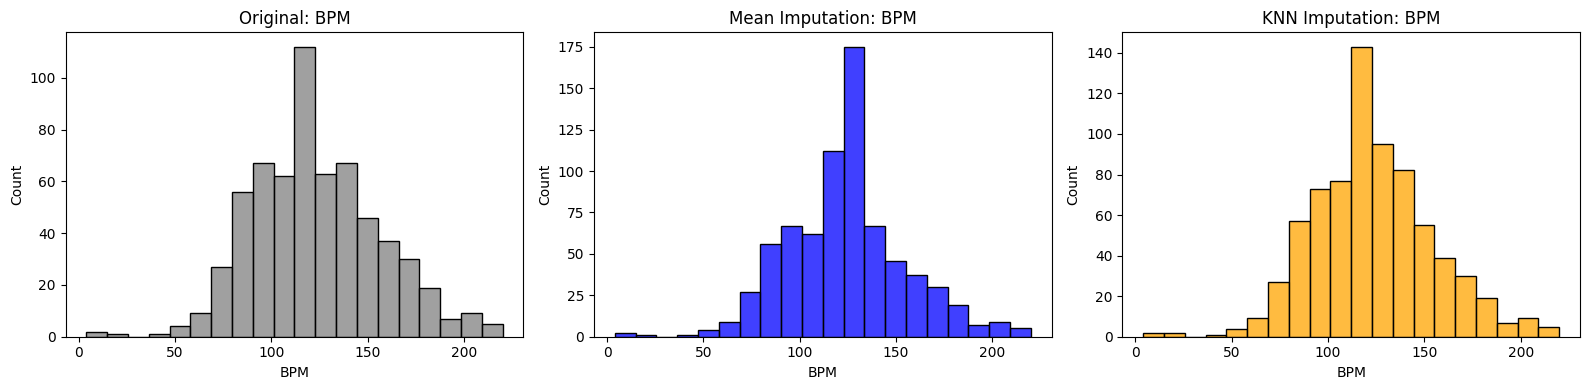

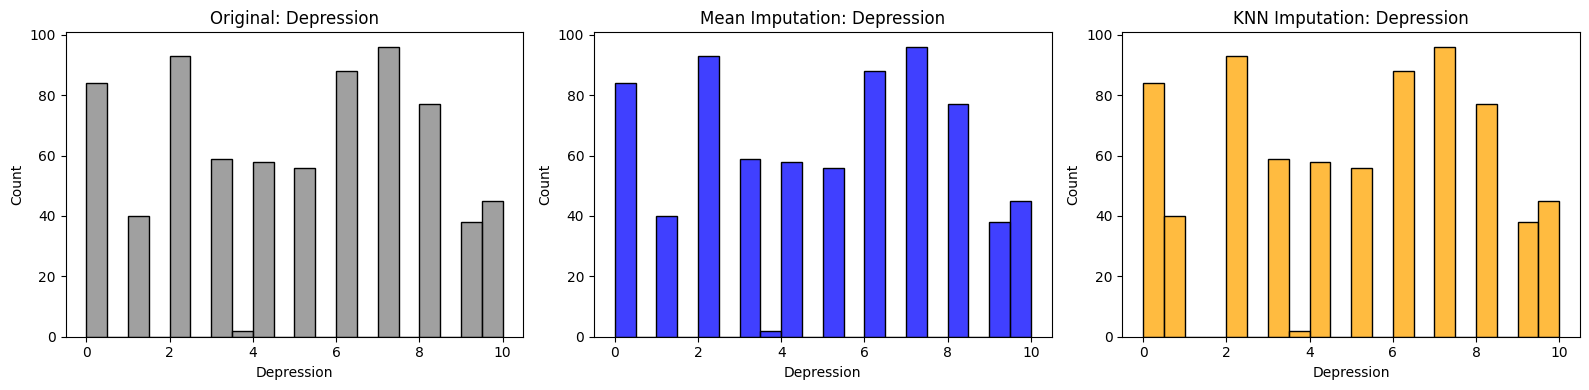

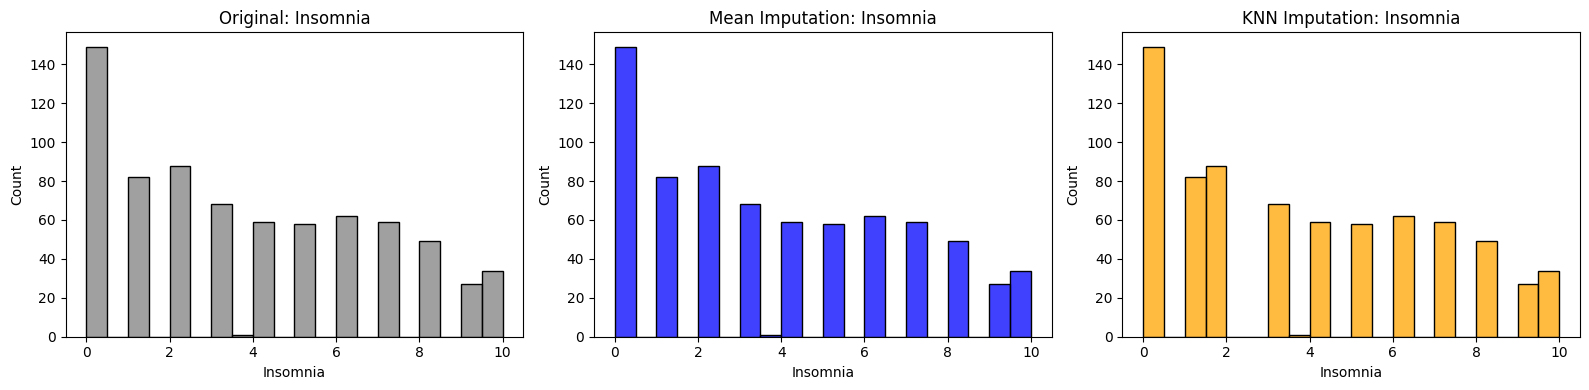

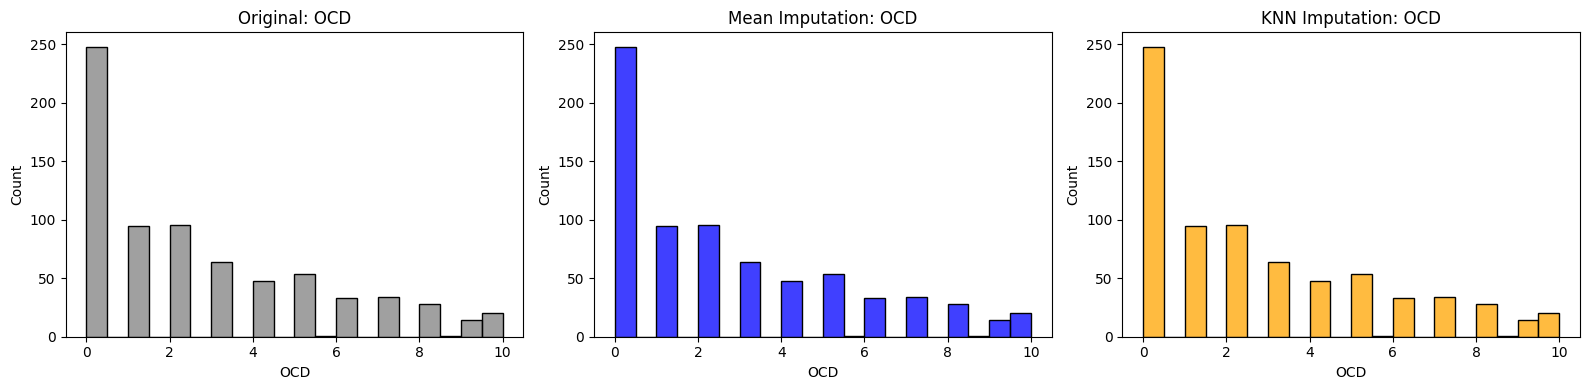

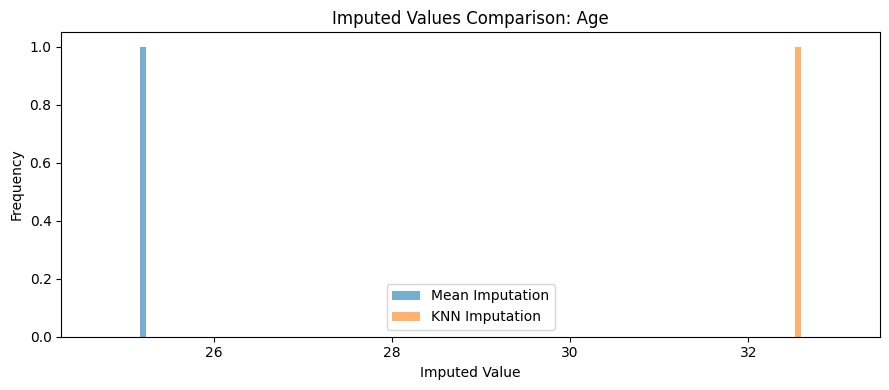

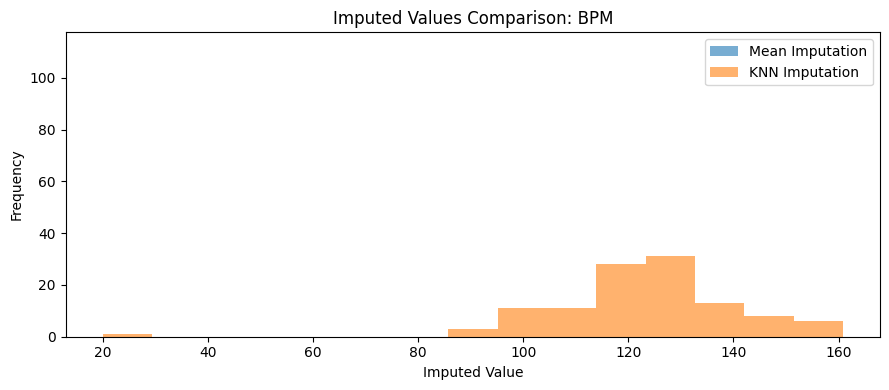

In [23]:
# ------------------------------------------------------------
# 13. COMPARE MEAN AND KNN IMPUTATION
# ------------------------------------------------------------

comparison = []

for col in numeric_predictors:
    comparison.append({
        "Feature": col,
        "Original Missing": df[col].isnull().sum(),
        "Mean Imputation Mean": df_mean[col].mean(),
        "KNN Imputation Mean": df_knn[col].mean(),
        "Mean Imputation Std": df_mean[col].std(),
        "KNN Imputation Std": df_knn[col].std()
    })

imputation_comparison = pd.DataFrame(comparison)

print("\nMean vs KNN comparison:")
display(imputation_comparison.round(2))

# Compare distributions using histograms
for col in numeric_predictors:

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Original observed values
    sns.histplot(
        df[col].dropna(),
        bins=20,
        color="gray",
        ax=axes[0]
    )
    axes[0].set_title(f"Original: {col}")

    # Mean imputed values
    sns.histplot(
        df_mean[col],
        bins=20,
        color="blue",
        ax=axes[1]
    )
    axes[1].set_title(f"Mean Imputation: {col}")

    # KNN imputed values
    sns.histplot(
        df_knn[col],
        bins=20,
        color="orange",
        ax=axes[2]
    )
    axes[2].set_title(f"KNN Imputation: {col}")

    plt.tight_layout()
    plt.show()

# Compare only the values that were originally missing
for col in numeric_predictors:

    missing_mask = df[col].isna()

    if missing_mask.sum() == 0:
        continue

    plt.figure(figsize=(9, 4))

    plt.hist(
        df_mean.loc[missing_mask, col],
        bins=15,
        alpha=0.6,
        label="Mean Imputation"
    )

    plt.hist(
        df_knn.loc[missing_mask, col],
        bins=15,
        alpha=0.6,
        label="KNN Imputation"
    )

    plt.title(f"Imputed Values Comparison: {col}")
    plt.xlabel("Imputed Value")
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [24]:
# 14. SCALING: MIN-MAX NORMALIZATION
# ------------------------------------------------------------

# Scale continuous numeric predictors only.
# Do not scale the target, categorical variables, or binary fields.

scaling_columns = [
    col for col in numeric_predictors
    if df_mean[col].nunique(dropna=True) > 2
]

df_minmax = df_mean.copy()

if scaling_columns:
    minmax_scaler = MinMaxScaler()

    df_minmax[scaling_columns] = minmax_scaler.fit_transform(
        df_minmax[scaling_columns]
    )

print("\nMin-Max scaled data:")
display(df_minmax[scaling_columns].head())


Min-Max scaled data:


,Age,Hours per day,BPM,Depression,Insomnia,OCD
0,0.10,0.12,0.70,0.00,0.10,0.00
1,0.67,0.06,0.53,0.20,0.20,0.10
2,0.10,0.17,0.59,0.70,1.00,0.20
3,0.65,0.10,0.37,0.70,0.30,0.30
4,0.10,0.17,0.48,0.20,0.50,0.90


In [25]:
# ------------------------------------------------------------
# 15. SCALING: Z-SCORE STANDARDIZATION
# ------------------------------------------------------------

df_standard = df_mean.copy()

if scaling_columns:
    standard_scaler = StandardScaler()

    df_standard[scaling_columns] = standard_scaler.fit_transform(
        df_standard[scaling_columns]
    )

print("\nZ-score standardized data:")
display(df_standard[scaling_columns].head())


Z-score standardized data:


,Age,Hours per day,BPM,Depression,Insomnia,OCD
0,-0.60,-0.19,1.08,-1.58,-0.89,-0.93
1,3.14,-0.68,-0.14,-0.92,-0.56,-0.58
2,-0.60,0.14,0.29,0.73,2.03,-0.22
3,2.97,-0.35,-1.30,0.73,-0.24,0.13
4,-0.60,0.14,-0.54,-0.92,0.41,2.24



Scaling comparison:


,Feature,Original Mean,Original Std,MinMax Min,MinMax Max,ZScore Mean,ZScore Std
0,Age,25.21,12.05,0.00,1.00,0.00,1.00
1,Hours per day,3.57,3.03,0.00,1.00,-0.00,1.00
2,BPM,123.21,30.29,0.00,1.00,-0.00,1.00
3,Depression,4.80,3.03,0.00,1.00,-0.00,1.00
4,Insomnia,3.74,3.09,0.00,1.00,-0.00,1.00
5,OCD,2.64,2.84,0.00,1.00,-0.00,1.00


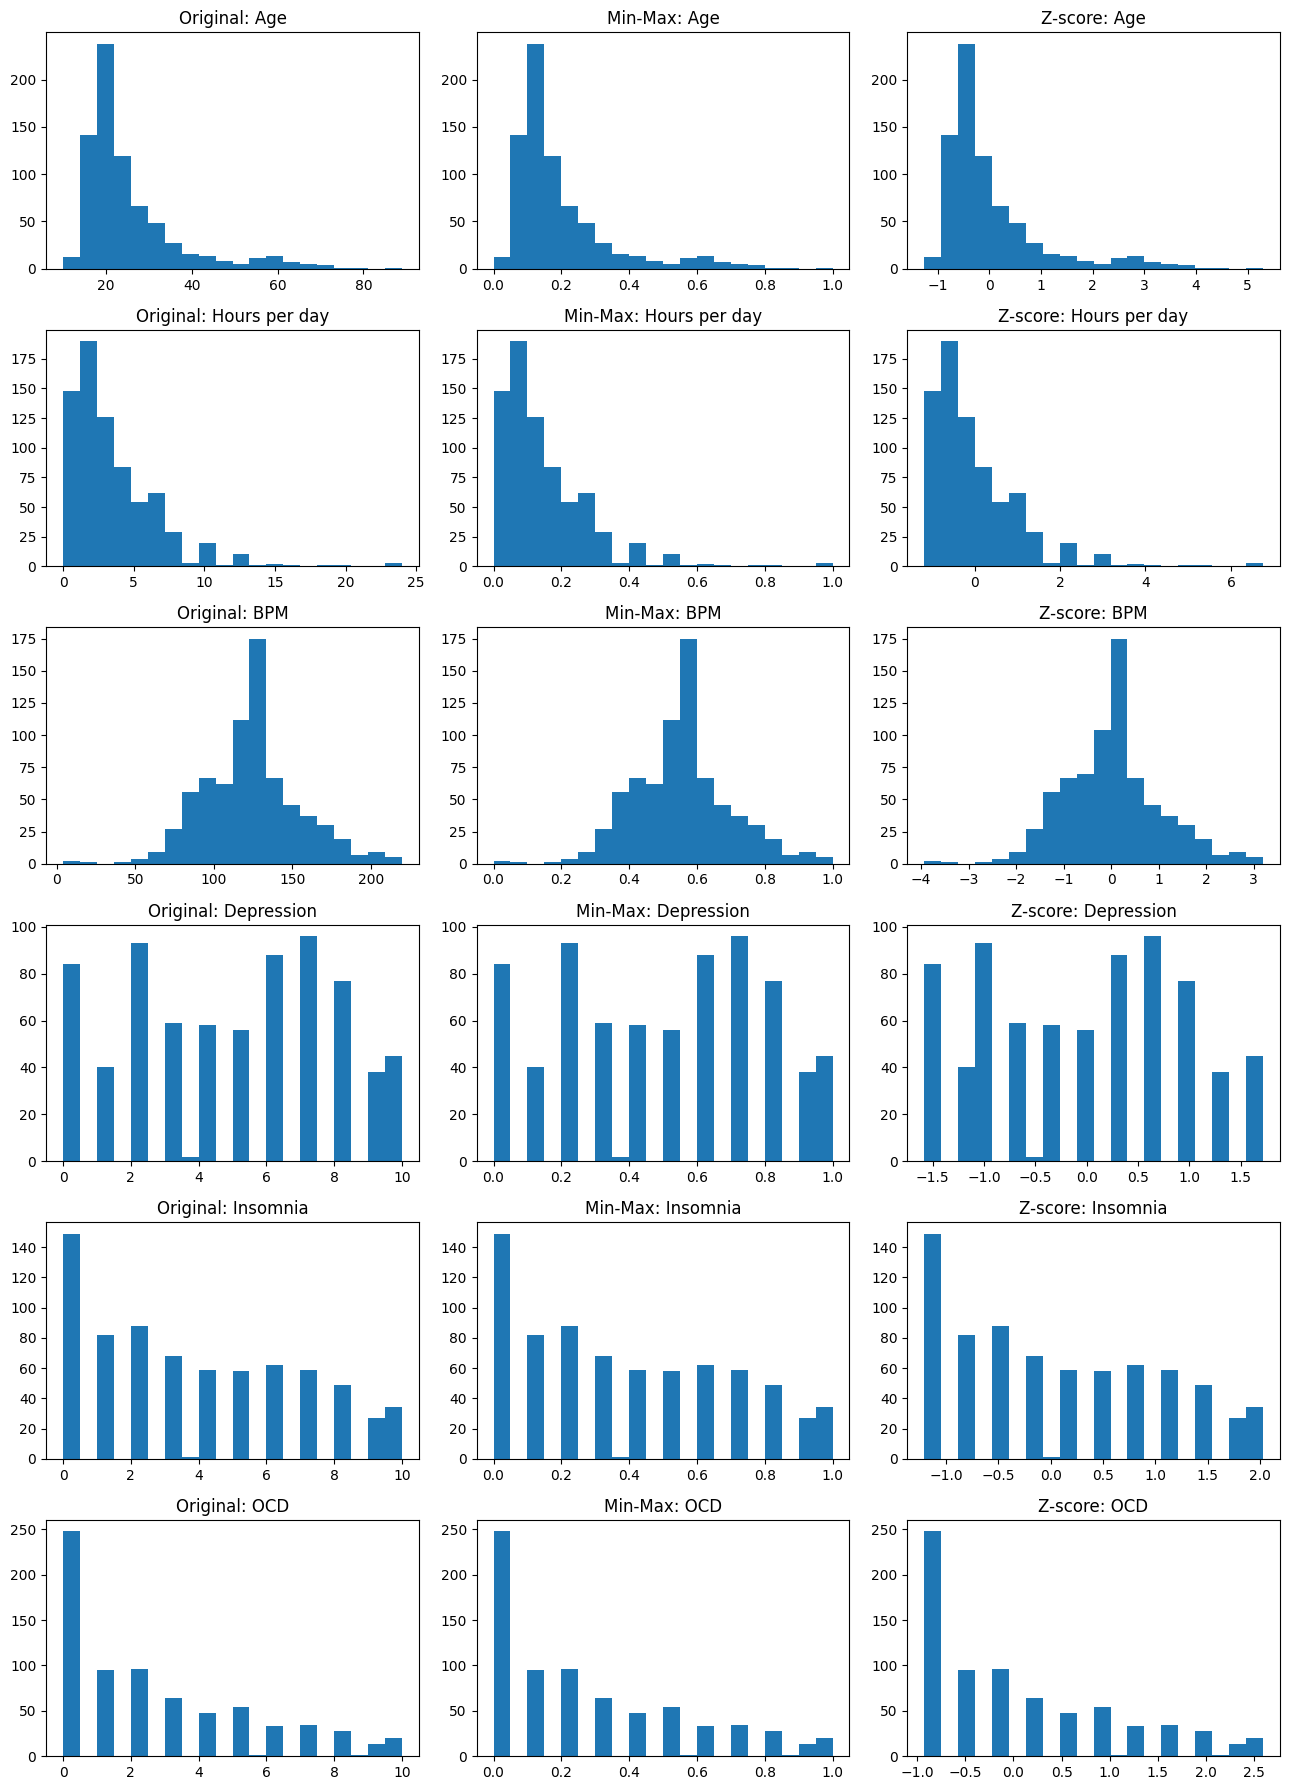

In [26]:

# ------------------------------------------------------------
# 16. COMPARE SCALING METHODS (FASTER VERSION)
# ------------------------------------------------------------

scaling_comparison_df = pd.DataFrame({
    "Feature": scaling_columns,
    "Original Mean": [df_mean[col].mean() for col in scaling_columns],
    "Original Std": [df_mean[col].std() for col in scaling_columns],
    "MinMax Min": [df_minmax[col].min() for col in scaling_columns],
    "MinMax Max": [df_minmax[col].max() for col in scaling_columns],
    "ZScore Mean": [df_standard[col].mean() for col in scaling_columns],
    "ZScore Std": [df_standard[col].std() for col in scaling_columns]
})

print("\nScaling comparison:")
display(scaling_comparison_df.round(2))

# Plot all features in one figure
fig, axes = plt.subplots(
    len(scaling_columns), 3,
    figsize=(13, 3 * len(scaling_columns))
)

if len(scaling_columns) == 1:
    axes = np.array([axes])

for i, col in enumerate(scaling_columns):

    axes[i, 0].hist(df_mean[col], bins=20)
    axes[i, 0].set_title(f"Original: {col}")

    axes[i, 1].hist(df_minmax[col], bins=20)
    axes[i, 1].set_title(f"Min-Max: {col}")

    axes[i, 2].hist(df_standard[col], bins=20)
    axes[i, 2].set_title(f"Z-score: {col}")

plt.tight_layout()
plt.show()

In [27]:
# ------------------------------------------------------------
# 17. FINAL DATA QUALITY CHECK
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL DATA QUALITY CHECK")
print("=" * 60)

print("Original cleaned dataset:", df.shape)
print("Mean-imputed dataset:", df_mean.shape)
print("KNN-imputed dataset:", df_knn.shape)
print("Min-Max dataset:", df_minmax.shape)
print("Standardized dataset:", df_standard.shape)

print("\nRemaining missing values:")
print("Mean:", df_mean.isnull().sum().sum())
print("KNN:", df_knn.isnull().sum().sum())

print("\nRemaining duplicates:")
print("Mean:", df_mean.duplicated().sum())
print("KNN:", df_knn.duplicated().sum())


FINAL DATA QUALITY CHECK
Original cleaned dataset: (736, 31)
Mean-imputed dataset: (736, 31)
KNN-imputed dataset: (736, 31)
Min-Max dataset: (736, 31)
Standardized dataset: (736, 31)

Remaining missing values:
Mean: 0
KNN: 0

Remaining duplicates:
Mean: 0
KNN: 0


In [28]:
# ------------------------------------------------------------
# 18. SAVE OUTPUT FILES FOR THE TEAM
# ------------------------------------------------------------

# Keep the cleaned dataset with its original categories.
df.to_csv(
    f"{OUTPUT_DIR}/01_cleaned_preserving_categories.csv",
    index=False
)

# Imputation alternatives.
df_mean.to_csv(
    f"{OUTPUT_DIR}/02_mean_imputed.csv",
    index=False
)

df_knn.to_csv(
    f"{OUTPUT_DIR}/03_knn_imputed.csv",
    index=False
)

# Scaling alternatives, based on mean-imputed data.
df_minmax.to_csv(
    f"{OUTPUT_DIR}/04_minmax_scaled.csv",
    index=False
)

df_standard.to_csv(
    f"{OUTPUT_DIR}/05_zscore_standardized.csv",
    index=False
)

# Save reports.
missing_summary.to_csv(
    f"{OUTPUT_DIR}/missing_values_report.csv"
)

outlier_df.to_csv(
    f"{OUTPUT_DIR}/outlier_report.csv",
    index=False
)

imputation_comparison.to_csv(
    f"{OUTPUT_DIR}/imputation_comparison.csv",
    index=False
)

scaling_comparison_df.to_csv(
    f"{OUTPUT_DIR}/scaling_comparison.csv",
    index=False
)

print("\nAll files saved in:", OUTPUT_DIR)
print("Stage 1 completed successfully!")


All files saved in: prepro_data
Stage 1 completed successfully!


# Music & Mental Health Survey
## Stage 1: Data Understanding, Cleaning, and Preprocessing

### 1. Project Overview

This project uses the **Music & Mental Health Survey Results** dataset from Kaggle.

The main objective of this stage is to understand the dataset, identify data-quality problems, clean invalid values, handle missing data, investigate outliers, and compare different preprocessing methods.

This stage prepares the dataset for the next stages of the project:

1. Encoding and discretization
2. Feature selection
3. Feature construction and model performance evaluation

**Important:** Stage 1 focuses on data preparation. We have not performed final feature selection or predictive modeling.

---

### 2. Dataset Loading and Initial Exploration

We started by loading the CSV file using Pandas.

The following operations were performed:

- Displayed the first five observations.
- Examined the number of rows and columns.
- Inspected feature names and data types.
- Generated descriptive statistics.
- Identified numerical and categorical features.

**Purpose:** Understand the structure of the dataset before making any modifications.

### 3. Missing-Value Analysis

We investigated missing values using:

- `isnull().sum()` to count missing values.
- Missing-value percentages for each feature.
- A bar chart to compare missing-value percentages.
- A heatmap to visualize the distribution of missing values.

We also considered different representations of missing data:

- NaN
- NULL values
- Empty strings
- Common text representations such as "NA" and "None"

Empty strings and common missing-value strings in categorical columns were converted to NaN.

**Why is this important?**

Missing values can affect statistical calculations, distance-based algorithms, and machine-learning models. Therefore, they must be identified before applying preprocessing methods.

### 4. Duplicate Removal

We identified duplicate observations using:

`df.duplicated().sum()`

Duplicate rows were removed using:

`df.drop_duplicates()`

**Purpose:** Avoid counting identical observations more than once.

### 5. Data Cleaning

We performed several cleaning operations:

- Removed unnecessary spaces from column names.
- Removed leading and trailing spaces from text values.
- Standardized Yes/No representations.
- Converted empty strings and common missing-value strings into NaN.
- Removed the Timestamp column because it was not needed for our planned analysis.
- Identified constant columns and removed columns without meaningful variation.

Categorical variables were preserved. We did not apply one-hot encoding or ordinal encoding in this stage because those operations belong to Stage 2.

### 6. Numerical Validation

We converted the expected numerical features into numeric data types and checked their valid ranges.

The following rules were applied:

| Feature | Validation rule |
|---|---|
| Age | Values below 10 or above 100 treated as invalid |
| Hours per day | Must be between 0 and 24 |
| BPM | Must be greater than 0 |
| Anxiety | Must be between 0 and 10 |
| Depression | Must be between 0 and 10 |
| Insomnia | Must be between 0 and 10 |
| OCD | Must be between 0 and 10 |

Invalid values were replaced with NaN instead of deleting the entire observation.

**Important distinction:**

Zero is not automatically considered missing.

For example:

- Anxiety = 0 is a valid response.
- Depression = 0 is a valid response.
- Hours per day = 0 can mean the respondent does not listen to music.
- BPM = 0 is treated as invalid.
- Age = 0 is treated as invalid.

Numerical values are displayed with two decimal places for presentation purposes. This does not necessarily mean that the original values are rounded or modified.

### 7. Outlier Detection

We used the Interquartile Range (IQR) method to identify potential outliers.

The formula is:

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

Values outside these boundaries were flagged as potential outliers.

We also generated boxplots for numerical features.

**Important:** We did not automatically remove outliers. An unusual survey response is not necessarily an incorrect observation.

The outlier report helps us understand the distributions and identify values that may require further investigation.

### 8. Numerical and Categorical Feature Identification

After cleaning, we separated the features into two groups:

**Numerical features:**
- Age
- Hours per day
- BPM
- Anxiety
- Depression
- Insomnia
- OCD

The actual columns depend on the dataset and the cleaning results.

**Categorical features:**
- Primary streaming service
- Fav genre
- While working
- Instrumentalist
- Composer
- Music effects
- Frequency-related categorical variables
- Other categorical survey responses

For the initial Anxiety prediction experiment, Anxiety was excluded from the numerical predictor list because it was considered the target variable.

### 9. Missing-Value Treatment: Mean Imputation

We applied mean imputation to numerical predictor features.

Mean imputation replaces missing numerical values with the arithmetic mean of the corresponding feature.

Formula:

Mean = Sum of observed values / Number of observed values

We used Scikit-learn's `SimpleImputer(strategy="mean")`.

For categorical features, we used the most frequent category (mode).

**Advantages:**
- Simple to implement.
- Fast to execute.
- Preserves the number of observations.

**Limitations:**
- Reduces variability in the affected feature.
- Can distort the original distribution.
- May be inappropriate for highly skewed features.

### 10. Missing-Value Treatment: KNN Imputation

We also applied K-Nearest Neighbors (KNN) imputation.

KNN estimates missing numerical values using observations that are similar to the incomplete observation.

We used:

- `StandardScaler` temporarily before calculating distances.
- `KNNImputer`
- `n_neighbors=5`
- `weights="distance"`

Distance-based imputation is sensitive to feature scales. Therefore, temporary standardization was applied before KNN.

Categorical features were filled using the most frequent category because ordinary numerical KNN imputation is not directly appropriate for unencoded categorical variables.

**Advantages:**
- Uses relationships between observations.
- Can preserve more variation than mean imputation.
- Can provide more individualized estimates.

**Limitations:**
- More computationally expensive than mean imputation.
- Sensitive to feature selection and distance calculations.
- Results depend on the selected number of neighbors.

### 11. Mean vs. KNN Comparison

We compared the two imputation methods using:

- Original number of missing values.
- Mean after imputation.
- Standard deviation after imputation.
- Distribution plots.
- Comparison of values inserted into originally missing positions.

The comparison helps us understand how each method changes the data.

**Expected observation:**

Mean imputation inserts the same mean value into every missing position in a feature.

KNN imputation can produce different estimated values depending on the nearest observations.

Therefore, KNN may preserve more variation, although it is not automatically the better method.

### 12. Feature Scaling

After imputation, we compared two scaling techniques.

#### 12.1 Min-Max Normalization

Min-Max scaling transforms values into a range between 0 and 1.

Formula:

X_scaled = (X - X_min) / (X_max - X_min)

We used `MinMaxScaler()`.

**Purpose:** Bring numerical features with different ranges into a common scale.

#### 12.2 Z-Score Standardization

Z-score standardization transforms values based on their mean and standard deviation.

Formula:

Z = (X - Mean) / Standard Deviation

We used `StandardScaler()`.

**Purpose:** Transform numerical features to have approximately zero mean and unit variance.

### 13. Min-Max vs. Z-Score Comparison

We compared the following statistics:

| Statistic | Min-Max | Z-score |
|---|---|---|
| Minimum | Usually 0 | Not fixed |
| Maximum | Usually 1 | Not fixed |
| Mean | Not necessarily 0 | Approximately 0 |
| Standard deviation | Not fixed | Approximately 1 |

We also generated histograms to compare:

1. Original numerical distributions.
2. Min-Max scaled distributions.
3. Z-score standardized distributions.

KDE calculations were omitted to reduce execution time.

**Important:** Scaling changes the numerical range but does not necessarily make a distribution normally distributed.

We applied scaling only to numerical predictors with more than two distinct values. Categorical features and the target variable were not scaled.

---

### 14. Generated Output Files

The preprocessing script generates a `processed_data` folder.

| File | Description |
|---|---|
| `01_cleaned_preserving_categories.csv` | Cleaned dataset with categorical values preserved |
| `02_mean_imputed.csv` | Dataset after mean/mode imputation |
| `03_knn_imputed.csv` | Dataset after KNN/mode imputation |
| `04_minmax_scaled.csv` | Dataset after Min-Max scaling |
| `05_zscore_standardized.csv` | Dataset after Z-score standardization |
| `missing_values_report.csv` | Missing-value statistics |
| `outlier_report.csv` | IQR-based outlier report |
| `imputation_comparison.csv` | Mean vs. KNN comparison |
| `scaling_comparison.csv` | Min-Max vs. Z-score comparison |

**Recommended input for the next team:** `01_cleaned_preserving_categories.csv`

This file preserves categorical values for encoding and discretization in Stage 2.

---

### 15. Handoff to the Next Stages

The next team should continue with the following tasks.

#### Stage 2: Encoding and Discretization

- Apply binary encoding to binary categorical features.
- Apply ordinal encoding to ordered frequency features.
- Apply one-hot encoding to multi-state nominal categorical features.
- Investigate entropy-based discretization.
- Apply 3-, 4-, or 5-level discretization.
- Develop an exploratory risk concept hierarchy using an appropriate mental-health score.

Any risk categories must be described as exploratory categories unless clinically validated thresholds are available.

#### Stage 3: Feature Selection

Use at least two feature-selection approaches:

**Filter method:**
- Pearson correlation or Mutual Information.

**Wrapper or embedded method:**
- Recursive Feature Elimination (RFE) or Lasso.

Extract and report the top K predictive features.

Compare the selected features across methods.

#### Stage 4: Feature Construction

Construct at least two domain-related interaction features.

Possible examples:

1. Music listening duration × genre frequency.
2. Number of genres listened to at least occasionally.

Evaluate model performance before and after feature construction.

For a regression task, report:
- MAE
- RMSE
- R²

Use the same train/test split and evaluation procedure for both experiments.

---

### 16. Important Methodological Considerations

1. Mean and KNN imputation are alternatives. The team should select the appropriate method based on the comparison and justify the decision.

2. The same applies to Min-Max and Z-score scaling.

3. The target variable must not be imputed when it is used as the prediction label. Rows with missing target values should be excluded from supervised training.

4. For final model evaluation, split the dataset into training and testing sets before fitting preprocessing transformations. Fit imputers, scalers, encoders, discretizers, and feature selectors on training data only, then apply them to the test data.

5. Avoid data leakage during feature selection and feature construction.

6. Self-reported Anxiety, Depression, Insomnia, and OCD scores are survey measurements, not clinical diagnoses.

### Conclusion

Stage 1 established the data-quality foundation for the project.

We inspected and cleaned the dataset, investigated missing values and outliers, compared two imputation approaches, and compared two feature-scaling methods.

The resulting cleaned dataset preserves categorical information and is ready for the next stages: encoding, discretization, feature selection, and feature construction.

## Stage 2: Categorical Encoding and Discretization

In this stage, we prepare the imputed dataset for categorical encoding and numerical discretization.

The main objectives are:

- Encode nominal categorical variables using One-Hot Encoding.
- Convert binary categorical variables into numerical values.
- Preserve the natural order of ordinal categorical variables.
- Apply discretization to selected numerical features and create higher-level concepts.

The KNN-imputed dataset from Stage 1 is used as the starting point. A final input validation is also performed before encoding.

The original target variable, `Anxiety`, is kept separate from the input features to prevent target leakage.

In [29]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler


# Load the KNN-imputed dataset.
possible_paths = [
    "data/03_knn_imputed.csv",
    "prepro_data/03_knn_imputed.csv",
    "03_knn_imputed.csv"
]

local_path = next(
    (path for path in possible_paths if Path(path).exists()),
    None
)

if local_path is not None:
    df_task2 = pd.read_csv(local_path)
else:
    data_url = (
        "https://raw.githubusercontent.com/"
        "RwinRad/Ai/main/data/03_knn_imputed.csv"
    )
    df_task2 = pd.read_csv(data_url)


print("Dataset loaded successfully.")
print("Shape:", df_task2.shape)


# Validate the BPM column.
# Values below 20 or above 300 are treated as implausible
# tempo values for this project.
invalid_bpm_mask = (
    (df_task2["BPM"] < 20) |
    (df_task2["BPM"] > 300)
)

print("Invalid BPM values:", invalid_bpm_mask.sum())

df_task2.loc[invalid_bpm_mask, "BPM"] = np.nan


# Correct tiny negative values caused by floating-point precision.
tiny_negative_hours = (
    (df_task2["Hours per day"] < 0) &
    (df_task2["Hours per day"] > -1e-8)
)

df_task2.loc[tiny_negative_hours, "Hours per day"] = 0


# Re-impute the invalid BPM values using KNN.
# Anxiety is excluded because it is the prediction target.
numeric_predictors = [
    "Age",
    "Hours per day",
    "BPM",
    "Depression",
    "Insomnia",
    "OCD"
]

scaler = StandardScaler()

numeric_scaled = scaler.fit_transform(
    df_task2[numeric_predictors]
)

knn_imputer = KNNImputer(
    n_neighbors=5,
    weights="distance"
)

numeric_imputed_scaled = knn_imputer.fit_transform(
    numeric_scaled
)

numeric_imputed = scaler.inverse_transform(
    numeric_imputed_scaled
)

df_task2[numeric_predictors] = numeric_imputed

# Restore integer values for features originally recorded as integers.
integer_like_columns = [
    "Age",
    "BPM",
    "Depression",
    "Insomnia",
    "OCD"
]

df_task2[integer_like_columns] = (
    df_task2[integer_like_columns].round().astype("int64")
)

# Remove floating-point precision artifacts.
df_task2["Hours per day"] = (
    df_task2["Hours per day"]
    .round(6)
    .clip(lower=0)
    + 0.0
)

# Final input validation.
print("\nFinal input validation:")
print("Shape:", df_task2.shape)
print("Remaining missing values:", df_task2.isnull().sum().sum())
print("BPM minimum:", round(df_task2["BPM"].min(), 2))
print("BPM maximum:", round(df_task2["BPM"].max(), 2))
print("Hours per day minimum:", round(df_task2["Hours per day"].min(), 6))

display(df_task2.head())

Dataset loaded successfully.
Shape: (736, 31)
Invalid BPM values: 2

Final input validation:
Shape: (736, 31)
Remaining missing values: 0
BPM minimum: 20
BPM maximum: 220
Hours per day minimum: 0.0


,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,BPM,...,Frequency [Pop],Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects
0,18,Spotify,3.00,Yes,Yes,Yes,Latin,Yes,Yes,156,...,Very frequently,Sometimes,Very frequently,Never,Sometimes,3.00,0,1,0,Improve
1,63,Pandora,1.50,Yes,No,No,Rock,Yes,No,119,...,Sometimes,Sometimes,Rarely,Very frequently,Rarely,7.00,2,2,1,Improve
2,18,Spotify,4.00,No,No,No,Video game music,No,Yes,132,...,Rarely,Never,Rarely,Rarely,Very frequently,7.00,7,10,2,No effect
3,61,YouTube Music,2.50,Yes,No,Yes,Jazz,Yes,Yes,84,...,Sometimes,Sometimes,Never,Never,Never,9.00,7,3,3,Improve
4,18,Spotify,4.00,Yes,No,No,R&B,Yes,No,107,...,Sometimes,Very frequently,Very frequently,Never,Rarely,7.00,2,5,9,Improve


### 2.1 Categorical Feature Identification

Categorical features are divided into three groups according to their meaning:

1. **Nominal features:** Categories with no natural order, such as music genre and streaming service.
2. **Binary features:** Features with only two possible values, such as Yes and No.
3. **Ordinal features:** Categories with a meaningful order, such as music-listening frequency.

The encoding method is selected according to each feature type.

In [30]:
# Binary categorical features
binary_columns = [
    "While working",
    "Instrumentalist",
    "Composer",
    "Exploratory",
    "Foreign languages"
]

# Ordinal categorical features
ordinal_columns = [
    col for col in df_task2.columns
    if col.startswith("Frequency [")
]

# Nominal categorical features
nominal_columns = [
    "Primary streaming service",
    "Fav genre",
    "Music effects"
]

print("Binary features:", binary_columns)
print("\nNumber of ordinal features:", len(ordinal_columns))
print(ordinal_columns)
print("\nNominal features:", nominal_columns)

print("\nObserved categories:")
for col in binary_columns + nominal_columns:
    print(f"\n{col}: {sorted(df_task2[col].dropna().unique())}")

for col in ordinal_columns:
    print(f"\n{col}: {sorted(df_task2[col].dropna().unique())}")

Binary features: ['While working', 'Instrumentalist', 'Composer', 'Exploratory', 'Foreign languages']

Number of ordinal features: 16
['Frequency [Classical]', 'Frequency [Country]', 'Frequency [EDM]', 'Frequency [Folk]', 'Frequency [Gospel]', 'Frequency [Hip hop]', 'Frequency [Jazz]', 'Frequency [K pop]', 'Frequency [Latin]', 'Frequency [Lofi]', 'Frequency [Metal]', 'Frequency [Pop]', 'Frequency [R&B]', 'Frequency [Rap]', 'Frequency [Rock]', 'Frequency [Video game music]']

Nominal features: ['Primary streaming service', 'Fav genre', 'Music effects']

Observed categories:

While working: ['No', 'Yes']

Instrumentalist: ['No', 'Yes']

Composer: ['No', 'Yes']

Exploratory: ['No', 'Yes']

Foreign languages: ['No', 'Yes']

Primary streaming service: ['Apple Music', 'I do not use a streaming service.', 'Other streaming service', 'Pandora', 'Spotify', 'YouTube Music']

Fav genre: ['Classical', 'Country', 'EDM', 'Folk', 'Gospel', 'Hip hop', 'Jazz', 'K pop', 'Latin', 'Lofi', 'Metal', 'Pop', '

### 2.2 Categorical Encoding

Different encoding methods are applied according to the feature types:

- Binary Encoding: Yes and No are mapped to 1 and 0.
- Ordinal Encoding: Music-listening frequency levels are mapped according to their natural order.
- One-Hot Encoding: Nominal features are converted into separate binary indicator columns.

The original target variable, `Anxiety`, is preserved and is not included in the encoding of input features.

In [31]:
# Create a separate dataset for encoding.
df_encoded = df_task2.copy()


# 1. Binary Encoding
binary_mapping = {
    "No": 0,
    "Yes": 1
}

for col in binary_columns:
    unexpected_values = (
        set(df_encoded[col].dropna().unique())
        - set(binary_mapping.keys())
    )

    if unexpected_values:
        raise ValueError(
            f"Unexpected values in {col}: {unexpected_values}"
        )

    df_encoded[col] = (
        df_encoded[col]
        .map(binary_mapping)
        .astype("int8")
    )


# 2. Ordinal Encoding
frequency_mapping = {
    "Never": 0,
    "Rarely": 1,
    "Sometimes": 2,
    "Very frequently": 3
}

for col in ordinal_columns:
    unexpected_values = (
        set(df_encoded[col].dropna().unique())
        - set(frequency_mapping.keys())
    )

    if unexpected_values:
        raise ValueError(
            f"Unexpected values in {col}: {unexpected_values}"
        )

    df_encoded[col] = (
        df_encoded[col]
        .map(frequency_mapping)
        .astype("int8")
    )


# 3. One-Hot Encoding for nominal features
df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_columns,
    dtype="int8"
)


print("Encoding completed successfully.")
print("Original shape:", df_task2.shape)
print("Encoded shape:", df_encoded.shape)

print("\nRemaining non-numeric columns:")
print(df_encoded.select_dtypes(include="object").columns.tolist())

display(df_encoded.head())

Encoding completed successfully.
Original shape: (736, 31)
Encoded shape: (736, 53)

Remaining non-numeric columns:
[]


,Age,Hours per day,While working,Instrumentalist,Composer,Exploratory,Foreign languages,BPM,Frequency [Classical],Frequency [Country],...,Fav genre_Lofi,Fav genre_Metal,Fav genre_Pop,Fav genre_R&B,Fav genre_Rap,Fav genre_Rock,Fav genre_Video game music,Music effects_Improve,Music effects_No effect,Music effects_Worsen
0,18,3.00,1,1,1,1,1,156,1,0,...,0,0,0,0,0,0,0,1,0,0
1,63,1.50,1,0,0,1,0,119,2,0,...,0,0,0,0,0,1,0,1,0,0
2,18,4.00,0,0,0,0,1,132,0,0,...,0,0,0,0,0,0,1,0,1,0
3,61,2.50,1,0,1,1,1,84,2,0,...,0,0,0,0,0,0,0,1,0,0
4,18,4.00,1,0,0,1,0,107,0,0,...,0,0,0,1,0,0,0,1,0,0


### 2.3 Entropy-Based Discretization

Discretization converts continuous numerical attributes into a smaller number of meaningful intervals.

In this project:

- The numerical Anxiety score is grouped into three descriptive score bands.
- Age and daily listening time are discretized using a Decision Tree with the Entropy criterion.
- Information Gain is used to determine the splitting thresholds.
- The resulting intervals provide higher-level representations of the original numerical features.

The Anxiety score groups are analytical categories and must not be interpreted as clinical diagnoses.

#### Note on Target Leakage

The `Anxiety_Score_Group` variable is derived directly from the original `Anxiety` score.

It is used as the target label for supervised entropy-based discretization and for stratified train-test splitting. It must not be used as an input feature when predicting `Anxiety`.

In subsequent modeling stages, the original target and its derived group must be excluded from the input feature set to prevent target leakage.

In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Create descriptive groups from the self-reported Anxiety score.
anxiety_bins = [-0.01, 3.33, 6.67, 10.01]

anxiety_labels = [
    "Lower score",
    "Middle score",
    "Higher score"
]

df_encoded["Anxiety_Score_Group"] = pd.cut(
    df_encoded["Anxiety"],
    bins=anxiety_bins,
    labels=anxiety_labels,
    include_lowest=True
)

print("Anxiety score group distribution:")
display(
    df_encoded["Anxiety_Score_Group"]
    .value_counts()
    .sort_index()
)


# Split the rows before learning entropy-based thresholds.
# The same split can be reused in later modeling stages.
train_indices, test_indices = train_test_split(
    df_encoded.index,
    test_size=0.20,
    random_state=42,
    stratify=df_encoded["Anxiety_Score_Group"]
)

print("\nTraining samples:", len(train_indices))
print("Testing samples:", len(test_indices))

# Save the exact train-test split for reproducibility.
split_dir = Path("task2_output")
split_dir.mkdir(exist_ok=True)

pd.Series(
    train_indices,
    name="row_index"
).to_csv(
    split_dir / "train_indices.csv",
    index=False
)

pd.Series(
    test_indices,
    name="row_index"
).to_csv(
    split_dir / "test_indices.csv",
    index=False
)

print("Train and test indices saved successfully.")

# Learn entropy-based cut points for selected numerical features.
features_to_discretize = [
    "Age",
    "Hours per day"
]

discretization_results = []

for feature in features_to_discretize:

    entropy_tree = DecisionTreeClassifier(
        criterion="entropy",
        max_leaf_nodes=4,
        min_samples_leaf=40,
        random_state=42
    )

    X_train = df_encoded.loc[
        train_indices, [feature]
    ]

    y_train = df_encoded.loc[
        train_indices, "Anxiety_Score_Group"
    ]

    entropy_tree.fit(X_train, y_train)

    # Extract the thresholds learned by the decision tree.
    thresholds = sorted(
        entropy_tree.tree_.threshold[
            entropy_tree.tree_.feature >= 0
        ].tolist()
    )

    # Build intervals using the learned cut points.
    bin_edges = [-np.inf] + thresholds + [np.inf]

    bin_labels = [
        f"Bin_{i + 1}"
        for i in range(len(bin_edges) - 1)
    ]

    new_column = f"{feature}_Entropy_Bin"

    df_encoded[new_column] = pd.cut(
        df_encoded[feature],
        bins=bin_edges,
        labels=bin_labels,
        include_lowest=True
    )

    discretization_results.append({
        "Feature": feature,
        "Number of Bins": len(bin_labels),
        "Cut Points": thresholds
    })


# Display the learned intervals.
discretization_summary = pd.DataFrame(
    discretization_results
)

print("\nEntropy-based discretization results:")
display(discretization_summary)

print("\nDiscretized feature distributions:")

for feature in features_to_discretize:
    new_column = f"{feature}_Entropy_Bin"

    print(f"\n{new_column}")
    display(df_encoded[new_column].value_counts().sort_index())

Anxiety score group distribution:


,count
Anxiety_Score_Group,
Lower score,177
Middle score,198
Higher score,361



Training samples: 588
Testing samples: 148
Train and test indices saved successfully.

Entropy-based discretization results:


,Feature,Number of Bins,Cut Points
0,Age,4,"[27.5, 31.5, 45.0]"
1,Hours per day,4,"[1.75, 2.25, 5.5]"



Discretized feature distributions:

Age_Entropy_Bin


,count
Age_Entropy_Bin,
Bin_1,549
Bin_2,50
Bin_3,81
Bin_4,56



Hours per day_Entropy_Bin


,count
Hours per day_Entropy_Bin,
Bin_1,165
Bin_2,173
Bin_3,264
Bin_4,134


### 2.4 Finalizing the Encoded Dataset

The final dataset combines:

- Binary-encoded features.
- Ordinal-encoded music frequency features.
- One-hot-encoded nominal features.
- Entropy-based discretized numerical features.

The original numerical `Anxiety` score is retained as the prediction target.

The derived Anxiety score group is kept separately as an ordered analytical label, not as an input feature.

In [33]:
# Convert discretized interval categories into ordered integer codes.
discretized_columns = [
    "Age_Entropy_Bin",
    "Hours per day_Entropy_Bin"
]

for col in discretized_columns:
    df_encoded[col] = (
        df_encoded[col]
        .cat.codes
        .astype("int8")
    )


# Encode the derived Anxiety score group.
anxiety_group_mapping = {
    "Lower score": 0,
    "Middle score": 1,
    "Higher score": 2
}

df_encoded["Anxiety_Score_Group"] = (
    df_encoded["Anxiety_Score_Group"]
    .map(anxiety_group_mapping)
    .astype("int8")
)


# Final validation.
print("Final dataset shape:", df_encoded.shape)

print("\nRemaining missing values:")
print(df_encoded.isnull().sum().sum())

print("\nNon-numeric columns:")
print(
    df_encoded.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

print("\nAnxiety score group mapping:")
print(anxiety_group_mapping)

print("\nFinal dataset preview:")
display(df_encoded.head())


# Save Task 2 outputs.
output_dir = Path("task2_output")
output_dir.mkdir(exist_ok=True)

df_encoded.to_csv(
    output_dir / "task2_encoded_discretized.csv",
    index=False
)

discretization_summary.to_csv(
    output_dir / "discretization_summary.csv",
    index=False
)

print("\nTask 2 outputs saved in:", output_dir)

Final dataset shape: (736, 56)

Remaining missing values:
0

Non-numeric columns:
[]

Anxiety score group mapping:
{'Lower score': 0, 'Middle score': 1, 'Higher score': 2}

Final dataset preview:


,Age,Hours per day,While working,Instrumentalist,Composer,Exploratory,Foreign languages,BPM,Frequency [Classical],Frequency [Country],...,Fav genre_R&B,Fav genre_Rap,Fav genre_Rock,Fav genre_Video game music,Music effects_Improve,Music effects_No effect,Music effects_Worsen,Anxiety_Score_Group,Age_Entropy_Bin,Hours per day_Entropy_Bin
0,18,3.00,1,1,1,1,1,156,1,0,...,0,0,0,0,1,0,0,0,0,2
1,63,1.50,1,0,0,1,0,119,2,0,...,0,0,1,0,1,0,0,2,3,0
2,18,4.00,0,0,0,0,1,132,0,0,...,0,0,0,1,0,1,0,2,0,2
3,61,2.50,1,0,1,1,1,84,2,0,...,0,0,0,0,1,0,0,2,3,2
4,18,4.00,1,0,0,1,0,107,0,0,...,1,0,0,0,1,0,0,2,0,2



Task 2 outputs saved in: task2_output


### 2.5 Encoding Validation

After applying categorical encoding, validation checks are performed to ensure that the transformations preserve the intended meaning of the original categorical features.

The validation includes:

- Checking that binary features contain only 0 and 1.
- Verifying that ordinal features preserve their predefined order.
- Ensuring that each One-Hot encoded categorical feature has exactly one active category per record.
- Checking for remaining missing values.

These checks help identify encoding errors and ensure the reliability of the transformed dataset.

In [34]:
# Encoding validation

validation_results = []


# 1. Validate Binary Encoding
for col in binary_columns:
    valid = df_encoded[col].dropna().isin([0, 1]).all()

    validation_results.append({
        "Feature Group": "Binary",
        "Feature": col,
        "Validation": "Values must be 0 or 1",
        "Result": "PASS" if valid else "FAIL"
    })


# 2. Validate Ordinal Encoding
for col in ordinal_columns:
    valid = df_encoded[col].dropna().isin([0, 1, 2, 3]).all()

    validation_results.append({
        "Feature Group": "Ordinal",
        "Feature": col,
        "Validation": "Values must be between 0 and 3",
        "Result": "PASS" if valid else "FAIL"
    })


# 3. Validate One-Hot Encoding
for source_col in nominal_columns:

    dummy_cols = [
        col for col in df_encoded.columns
        if col.startswith(source_col + "_")
    ]

    if not dummy_cols:
        valid = False
        validation = "Dummy columns must exist"

    else:
        binary_values_valid = (
            df_encoded[dummy_cols]
            .isin([0, 1])
            .all()
            .all()
        )

        exactly_one_active = (
            df_encoded[dummy_cols]
            .sum(axis=1)
            .eq(1)
            .all()
        )

        valid = binary_values_valid and exactly_one_active
        validation = "Exactly one active category per record"

    validation_results.append({
        "Feature Group": "One-Hot",
        "Feature": source_col,
        "Validation": validation,
        "Result": "PASS" if valid else "FAIL"
    })


# 4. Check remaining missing values
missing_count = df_encoded.isnull().sum().sum()

validation_results.append({
    "Feature Group": "Overall",
    "Feature": "Complete Dataset",
    "Validation": "No missing values",
    "Result": "PASS" if missing_count == 0 else "CHECK"
})


# Create validation report
encoding_validation_report = pd.DataFrame(validation_results)

display(encoding_validation_report)

print("\nDataset shape:", df_encoded.shape)
print("Total missing values:", missing_count)

print(
    "\nOverall result:",
    "PASS" if (
        encoding_validation_report["Result"] == "PASS"
    ).all() else "CHECK"
)

,Feature Group,Feature,Validation,Result
0,Binary,While working,Values must be 0 or 1,PASS
1,Binary,Instrumentalist,Values must be 0 or 1,PASS
2,Binary,Composer,Values must be 0 or 1,PASS
3,Binary,Exploratory,Values must be 0 or 1,PASS
4,Binary,Foreign languages,Values must be 0 or 1,PASS
5,Ordinal,Frequency [Classical],Values must be between 0 and 3,PASS
6,Ordinal,Frequency [Country],Values must be between 0 and 3,PASS
7,Ordinal,Frequency [EDM],Values must be between 0 and 3,PASS
8,Ordinal,Frequency [Folk],Values must be between 0 and 3,PASS
9,Ordinal,Frequency [Gospel],Values must be between 0 and 3,PASS



Dataset shape: (736, 56)
Total missing values: 0

Overall result: PASS


### 2.6.1 Discretization Distribution Analysis

After determining the entropy-based cut points, the distribution of records across the resulting intervals is examined.

For each discretized feature, the following information is reported:

- Interval boundaries.
- Number of records in each interval.
- Percentage of the dataset belonging to each interval.

This analysis helps evaluate whether the discretization process produces sufficiently populated intervals or highly imbalanced groups.

The distribution of the three descriptive Anxiety score groups is also reported.

In [35]:
import ast

# Prepare a distribution report
distribution_results = []


def get_cut_points(value):
    """Convert stored cut points into a Python list."""
    if isinstance(value, str):
        value = ast.literal_eval(value)

    return list(value)


features_to_analyze = [
    ("Age", "Age_Entropy_Bin"),
    ("Hours per day", "Hours per day_Entropy_Bin")
]


for feature, bin_column in features_to_analyze:

    row = discretization_summary.loc[
        discretization_summary["Feature"] == feature
    ].iloc[0]

    cut_points = get_cut_points(row["Cut Points"])
    number_of_bins = int(row["Number of Bins"])

    bin_counts = (
        df_encoded[bin_column]
        .value_counts()
        .reindex(range(number_of_bins), fill_value=0)
    )

    for i in range(number_of_bins):

        if i == 0:
            interval = f"(-∞, {cut_points[0]:g}]"

        elif i == number_of_bins - 1:
            interval = f"({cut_points[-1]:g}, ∞)"

        else:
            interval = (
                f"({cut_points[i-1]:g}, "
                f"{cut_points[i]:g}]"
            )

        count = int(bin_counts.loc[i])

        distribution_results.append({
            "Feature": feature,
            "Bin Code": i,
            "Interval": interval,
            "Count": count,
            "Percentage": round(
                count / len(df_encoded) * 100, 2
            )
        })


# Include Anxiety score group distribution
anxiety_group_labels = {
    0: "Lower score",
    1: "Middle score",
    2: "Higher score"
}

anxiety_counts = (
    df_encoded["Anxiety_Score_Group"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
)

for code, label in anxiety_group_labels.items():

    count = int(anxiety_counts.loc[code])

    distribution_results.append({
        "Feature": "Anxiety score",
        "Bin Code": code,
        "Interval": label,
        "Count": count,
        "Percentage": round(
            count / len(df_encoded) * 100, 2
        )
    })


discretization_distribution = pd.DataFrame(
    distribution_results
)

display(discretization_distribution)

,Feature,Bin Code,Interval,Count,Percentage
0,Age,0,"(-∞, 27.5]",549,74.59
1,Age,1,"(27.5, 31.5]",50,6.79
2,Age,2,"(31.5, 45]",81,11.01
3,Age,3,"(45, ∞)",56,7.61
4,Hours per day,0,"(-∞, 1.75]",165,22.42
5,Hours per day,1,"(1.75, 2.25]",173,23.51
6,Hours per day,2,"(2.25, 5.5]",264,35.87
7,Hours per day,3,"(5.5, ∞)",134,18.21
8,Anxiety score,0,Lower score,177,24.05
9,Anxiety score,1,Middle score,198,26.90


### 2.6.2 Investigation of Listening-Time Discretization

The distribution of values within each listening-time interval is examined to identify possible response concentration or heaping.

Particular attention is given to the second interval, which may contain a high concentration of responses around two hours per day.

This analysis helps determine whether the learned intervals represent meaningful data patterns or are strongly influenced by repeated self-reported values.

In [36]:
# Inspect the second entropy-based interval.
hours_bin_2 = df_encoded.loc[
    df_encoded["Hours per day_Entropy_Bin"] == 1,
    "Hours per day"
]

print("Number of observations in Bin 2:", len(hours_bin_2))

print("\nValue distribution inside Bin 2:")

display(
    hours_bin_2
    .value_counts()
    .sort_index()
    .to_frame("Count")
)

print(
    "\nPercentage with exactly 2 hours:",
    round((hours_bin_2 == 2.0).mean() * 100, 2),
    "%"
)

Number of observations in Bin 2: 173

Value distribution inside Bin 2:


,Count
Hours per day,
2.00,173



Percentage with exactly 2 hours: 100.0 %


### 2.6.3 Preliminary Evaluation of Discretization

The relationship between the discretized features and the self-reported Anxiety score is examined using the held-out test partition.

Spearman correlation is used to inspect monotonic relationships between continuous features and Anxiety.

Chi-square tests are used to examine associations between discretized intervals and descriptive Anxiety score groups.

These analyses are exploratory and do not establish causal or clinical relationships.

In [37]:
from scipy.stats import spearmanr, chi2_contingency

# Use only the previously reserved test partition.
test_df = df_encoded.loc[test_indices].copy()


# 1. Spearman correlation for continuous features
print("Spearman Correlation on Test Data:")

for feature in ["Age", "Hours per day"]:

    rho, p_value = spearmanr(
        test_df[feature],
        test_df["Anxiety"]
    )

    print(
        f"{feature}: "
        f"rho={rho:.3f}, "
        f"p-value={p_value:.4f}"
    )


# 2. Chi-square tests for discretized features
print("\nChi-square Association Tests:")

for feature in [
    "Age_Entropy_Bin",
    "Hours per day_Entropy_Bin"
]:

    contingency = pd.crosstab(
        test_df[feature],
        test_df["Anxiety_Score_Group"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    n = contingency.to_numpy().sum()

    min_dimension = min(
        contingency.shape[0] - 1,
        contingency.shape[1] - 1
    )

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    )

    print(f"\nFeature: {feature}")
    print("Chi-square:", round(chi2, 3))
    print("p-value:", round(p_value, 4))
    print("Cramer's V:", round(cramers_v, 3))
    print("Minimum expected frequency:", round(expected.min(), 2))

    if expected.min() < 5:
        print(
            "Warning: Some expected cell counts are below 5. "
            "Interpret the Chi-square p-value cautiously."
        )

    display(contingency)

Spearman Correlation on Test Data:
Age: rho=-0.075, p-value=0.3638
Hours per day: rho=0.125, p-value=0.1291

Chi-square Association Tests:

Feature: Age_Entropy_Bin
Chi-square: 13.913
p-value: 0.0306
Cramer's V: 0.217
Minimum expected frequency: 2.36


Anxiety_Score_Group,0,1,2
Age_Entropy_Bin,,,
0,26,26,58
1,0,3,7
2,2,6,6
3,7,5,2



Feature: Hours per day_Entropy_Bin
Chi-square: 3.673
p-value: 0.7208
Cramer's V: 0.111
Minimum expected frequency: 6.39


Anxiety_Score_Group,0,1,2
Hours per day_Entropy_Bin,,,
0,10,14,14
1,9,9,20
2,10,11,24
3,6,6,15


### 2.6.4 Interpretation and Decision

The investigation of the entropy-based bins leads to the following observations:

- **Listening time (Hours per day):** Bin_2 contains only respondents who reported exactly 2 hours (173 of 173 observations). This interval therefore reflects heaping in self-reported values rather than a meaningful listening-time concept. On the held-out test set, the listening-time bins show no association with the Anxiety score groups (χ² p = 0.72, Cramér's V = 0.11), and the Spearman correlation is not significant (p = 0.13).
- **Age:** The Age bins show a moderate association with the Anxiety score groups on the test set (χ² p = 0.03, Cramér's V = 0.22). However, some expected cell counts are below 5, so this result is treated as tentative. The Spearman correlation for Age is not significant (p = 0.36), which suggests that the association is concentrated in specific age groups rather than being a simple monotonic trend.

**Decision:** The entropy-based bins are kept as exploratory features. The original numerical values of Age and Hours per day are retained alongside the discretized versions, so the feature-selection stage can compare both representations.

### 2.7 Visualization of Discretized Features

Bar charts are used to visualize the number of records in each discretized interval.

The visualizations provide an intuitive comparison of the distributions of Age and daily music-listening time after entropy-based discretization.

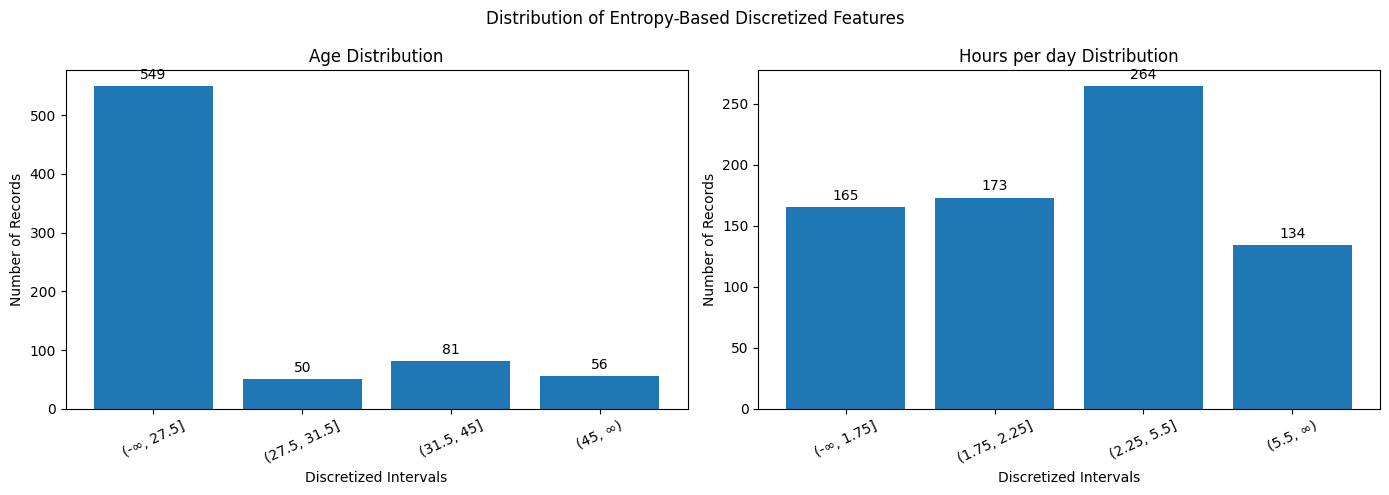

In [38]:
import matplotlib.pyplot as plt

features = ["Age", "Hours per day"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, features):

    plot_data = discretization_distribution[
        discretization_distribution["Feature"] == feature
    ]

    bars = ax.bar(
        plot_data["Interval"],
        plot_data["Count"]
    )

    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel("Discretized Intervals")
    ax.set_ylabel("Number of Records")

    ax.tick_params(
        axis="x",
        rotation=25
    )

    ax.bar_label(bars, padding=3)

plt.suptitle("Distribution of Entropy-Based Discretized Features")
plt.tight_layout()
plt.show()

### 2.8 Multi-Level Anxiety Score Concept Hierarchy

A multi-level concept hierarchy is constructed to represent the generalization of the self-reported Anxiety score.

The hierarchy consists of three levels:

- Level 0: Original numerical Anxiety scores (0–10).
- Level 1: Three descriptive score groups (Lower, Middle, and Higher).
- Level 2: Individual score values belonging to each group.

This hierarchy demonstrates how detailed numerical responses can be generalized into higher-level concepts.

The resulting categories are exploratory score groups and must not be interpreted as clinically validated anxiety risk levels.

Note: The Level 1 score groups (0–3, 4–6, 7–10) are defined manually using three equal-width bands. Entropy-based discretization was applied to Age and Hours per day, because Anxiety itself is the target label.

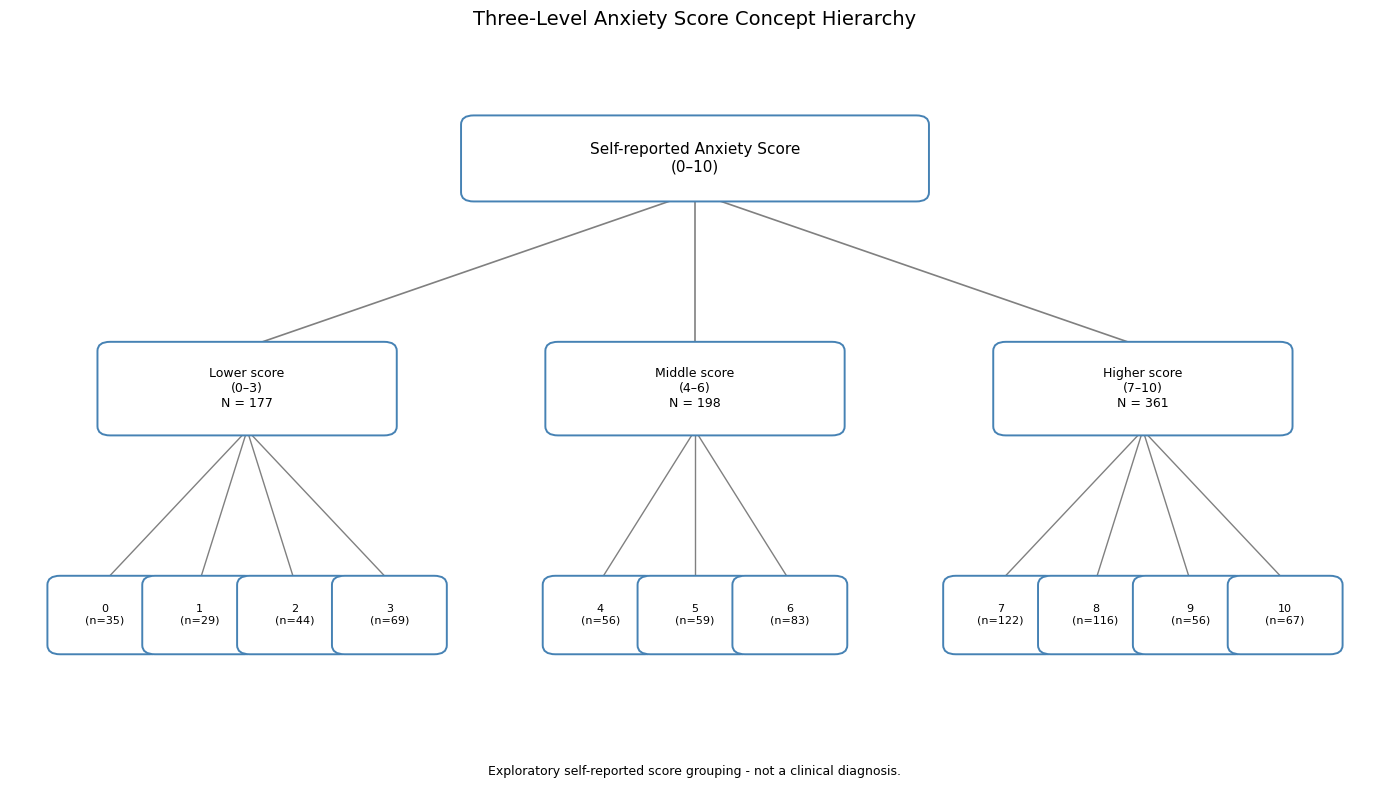

In [39]:
from matplotlib.patches import FancyBboxPatch

# Count observations for every original Anxiety score.
score_counts = (
    df_encoded["Anxiety"]
    .round()
    .astype(int)
    .value_counts()
    .reindex(range(11), fill_value=0)
)

# Define the three descriptive score groups.
groups = [
    {
        "label": "Lower score\n(0–3)",
        "scores": [0, 1, 2, 3],
        "center": 2.25,
        "children": [0.9, 1.8, 2.7, 3.6]
    },
    {
        "label": "Middle score\n(4–6)",
        "scores": [4, 5, 6],
        "center": 6.5,
        "children": [5.6, 6.5, 7.4]
    },
    {
        "label": "Higher score\n(7–10)",
        "scores": [7, 8, 9, 10],
        "center": 10.75,
        "children": [9.4, 10.3, 11.2, 12.1]
    }
]

fig, ax = plt.subplots(figsize=(14, 8))

ax.set_xlim(0, 13)
ax.set_ylim(1, 10)
ax.axis("off")


def add_node(x, y, width, height, label, fontsize=9):

    node = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width,
        height,
        boxstyle="round,pad=0.12",
        facecolor="white",
        edgecolor="steelblue",
        linewidth=1.4,
        zorder=2
    )

    ax.add_patch(node)

    ax.text(
        x,
        y,
        label,
        ha="center",
        va="center",
        fontsize=fontsize,
        zorder=3
    )


# Level 0: Root concept
root_x = 6.5
root_y = 8.6

# Draw connections before the nodes.
for group in groups:

    group_x = group["center"]

    # Root to score group
    ax.plot(
        [root_x, group_x],
        [8.15, 6.1],
        color="gray",
        linewidth=1.2,
        zorder=1
    )

    # Score group to individual scores
    for child_x in group["children"]:

        ax.plot(
            [group_x, child_x],
            [5.0, 3.0],
            color="gray",
            linewidth=1.0,
            zorder=1
        )


# Draw root node
add_node(
    root_x,
    root_y,
    4.2,
    0.9,
    "Self-reported Anxiety Score\n(0–10)",
    fontsize=11
)


# Level 1: Descriptive score groups
for group in groups:

    group_count = int(
        score_counts.loc[group["scores"]].sum()
    )

    add_node(
        group["center"],
        5.55,
        2.6,
        1.0,
        f"{group['label']}\nN = {group_count}",
        fontsize=9
    )


# Level 2: Individual score values
for group in groups:

    for score, child_x in zip(
        group["scores"],
        group["children"]
    ):

        count = int(score_counts.loc[score])

        add_node(
            child_x,
            2.55,
            0.85,
            0.8,
            f"{score}\n(n={count})",
            fontsize=8
        )


ax.set_title(
    "Three-Level Anxiety Score Concept Hierarchy",
    fontsize=14,
    pad=20
)

fig.text(
    0.5,
    0.025,
    "Exploratory self-reported score grouping - not a clinical diagnosis.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

In [40]:
# Save final Task 2 outputs

output_dir = Path("task2_output")
output_dir.mkdir(exist_ok=True)

# Final encoded and discretized dataset
df_encoded.to_csv(
    output_dir / "task2_encoded_discretized.csv",
    index=False
)

# Discretization cut points
discretization_summary.to_csv(
    output_dir / "discretization_summary.csv",
    index=False
)

# Encoding validation report
encoding_validation_report.to_csv(
    output_dir / "encoding_validation_report.csv",
    index=False
)

# Interval distribution report
discretization_distribution.to_csv(
    output_dir / "discretization_distribution.csv",
    index=False
)

print("Task 2 files saved successfully.")

for file in output_dir.iterdir():
    print(file.name)

Task 2 files saved successfully.
discretization_summary.csv
test_indices.csv
train_indices.csv
task2_encoded_discretized.csv
discretization_distribution.csv
encoding_validation_report.csv


### Next Step: Task 3 – Feature Selection (IVS)

In the next stage, feature selection will be performed to identify the most informative predictive features. One Filter method (Pearson Correlation or Mutual Information) and one Wrapper or Embedded method (RFE or LASSO) will be applied to select the top-k features and reduce feature redundancy.